# AIGC 5500 Midterm: CNN, LSTM and Transformer on short-text intent

This notebook reproduces every table and figure in the report. With `RUN_EXPERIMENTS = False` it uses the committed results in `artifacts/`. With `True` it retrains everything, then measures cost. Both paths run the same code.

In [1]:
RUN_EXPERIMENTS = False
SEEDS = [42, 123, 999]
print('Seeds:', SEEDS)

Seeds: [42, 123, 999]


In [2]:
import subprocess, sys
from IPython.display import Image, display
import compare

if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, 'main.py'], check=True)
    subprocess.run([sys.executable, 'cost.py'], check=True)

## Tables
Every seed for every model, the settings chosen on validation, the ablations and the inference cost.

In [3]:
compare.main()


CORE COMPARISON: SNIPS {'train': 9983, 'val': 2139, 'test': 2140}
Model                   Seed 42  Seed 123  Seed 999     Mean   Spread
Baseline                 0.9812    0.9822    0.9827   0.9820   0.0014
CNN_Standard             0.9842    0.9822    0.9814   0.9826   0.0028
RNN_BiLSTM               0.9807    0.9803    0.9818   0.9809   0.0015
Transformer_Standard     0.9775    0.9738    0.9765   0.9759   0.0037

CORE COMPARISON: ATIS {'train': 3819, 'val': 819, 'test': 819}
Model                   Seed 42  Seed 123  Seed 999     Mean   Spread
Baseline                 0.7649    0.7602    0.7277   0.7509   0.0371
CNN_Standard             0.8462    0.8248    0.8387   0.8366   0.0214
RNN_BiLSTM               0.8343    0.8271    0.8483   0.8365   0.0212
Transformer_Standard     0.8019    0.7370    0.7765   0.7718   0.0649

TUNED SETTINGS (chosen on validation macro F1)
SNIPS  Baseline              lr=0.03    weight_decay=0.0
SNIPS  CNN_Standard          lr=0.01    weight_decay=0.01
SNIPS 


Figures written to artifacts/


## Data
Class balance and text length after duplicates are removed.

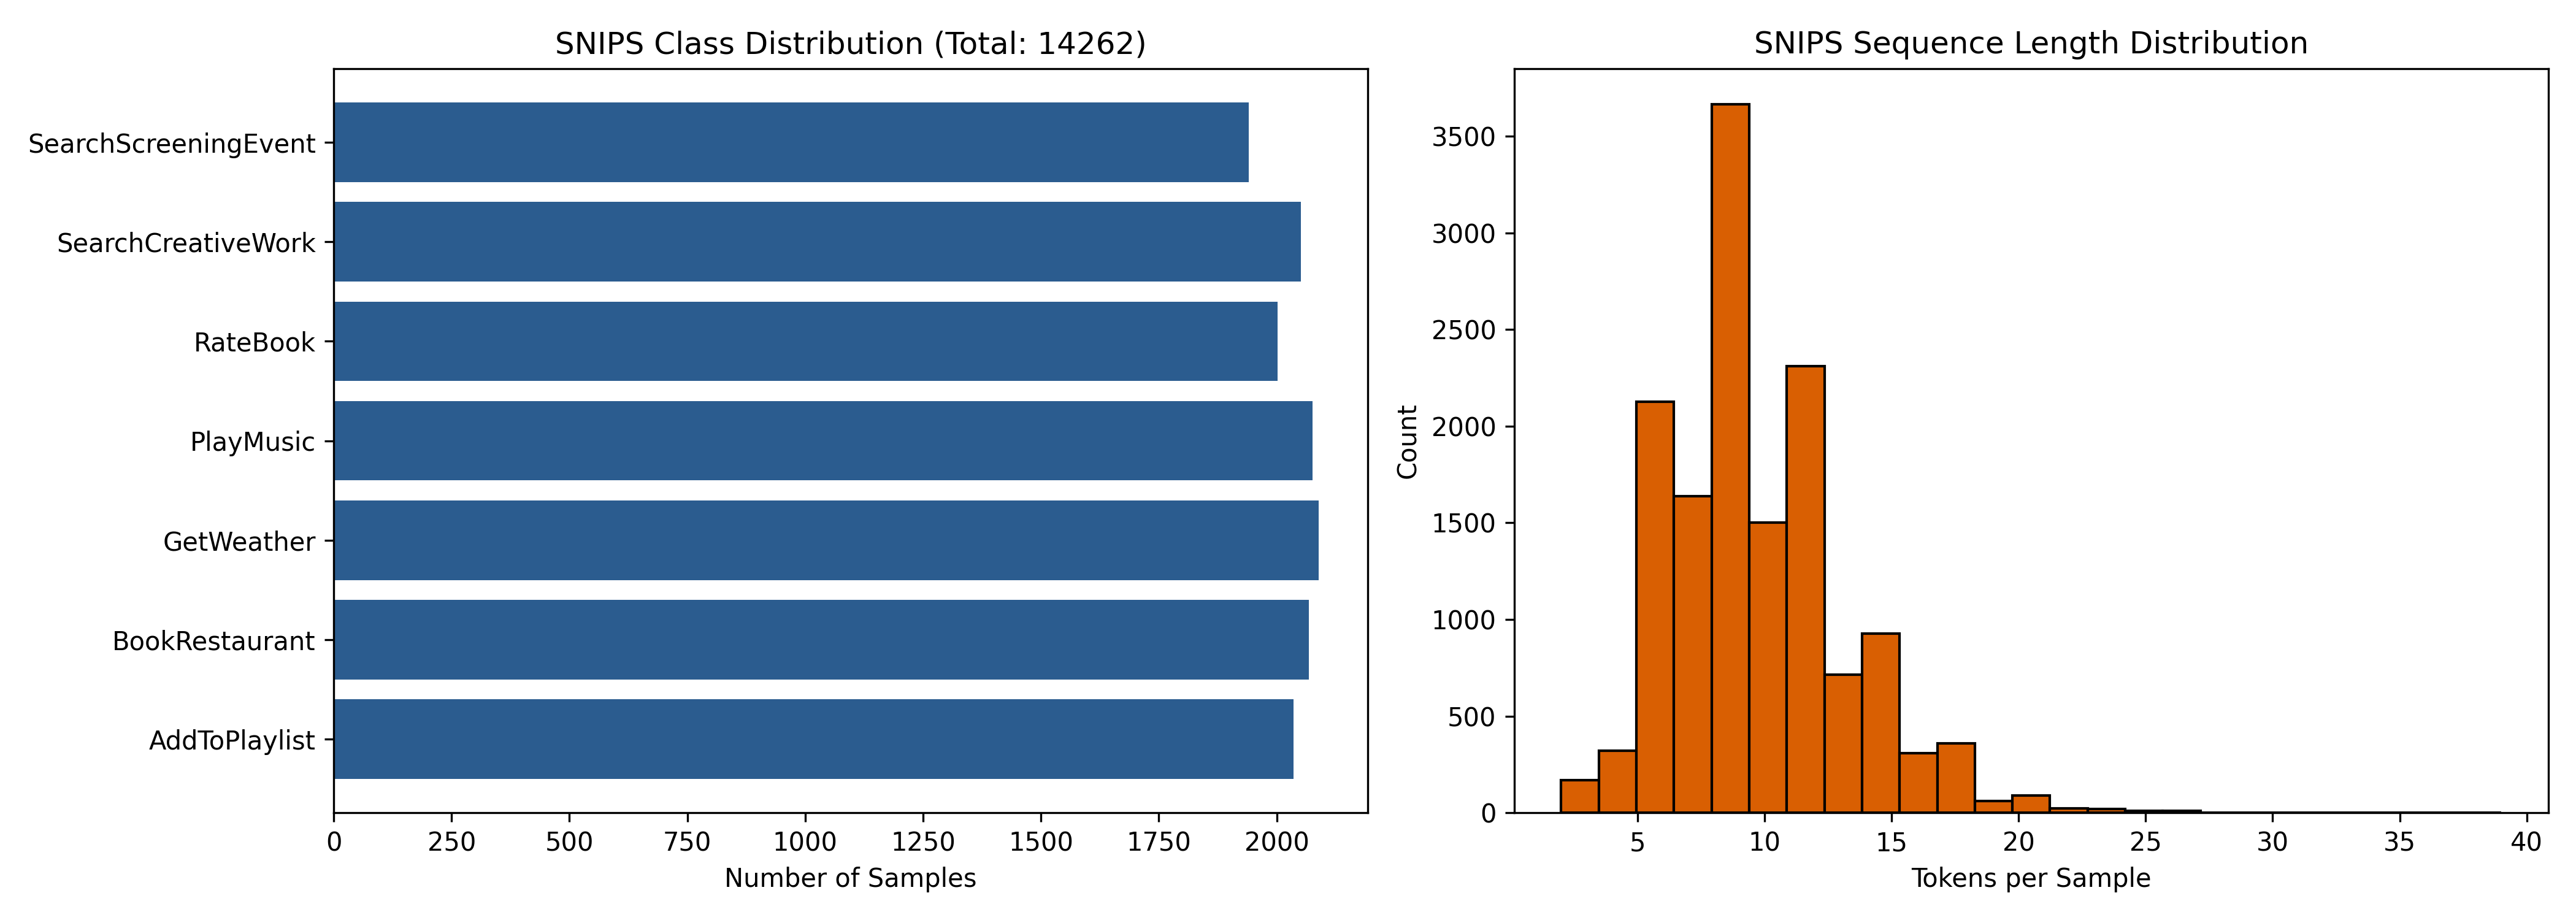

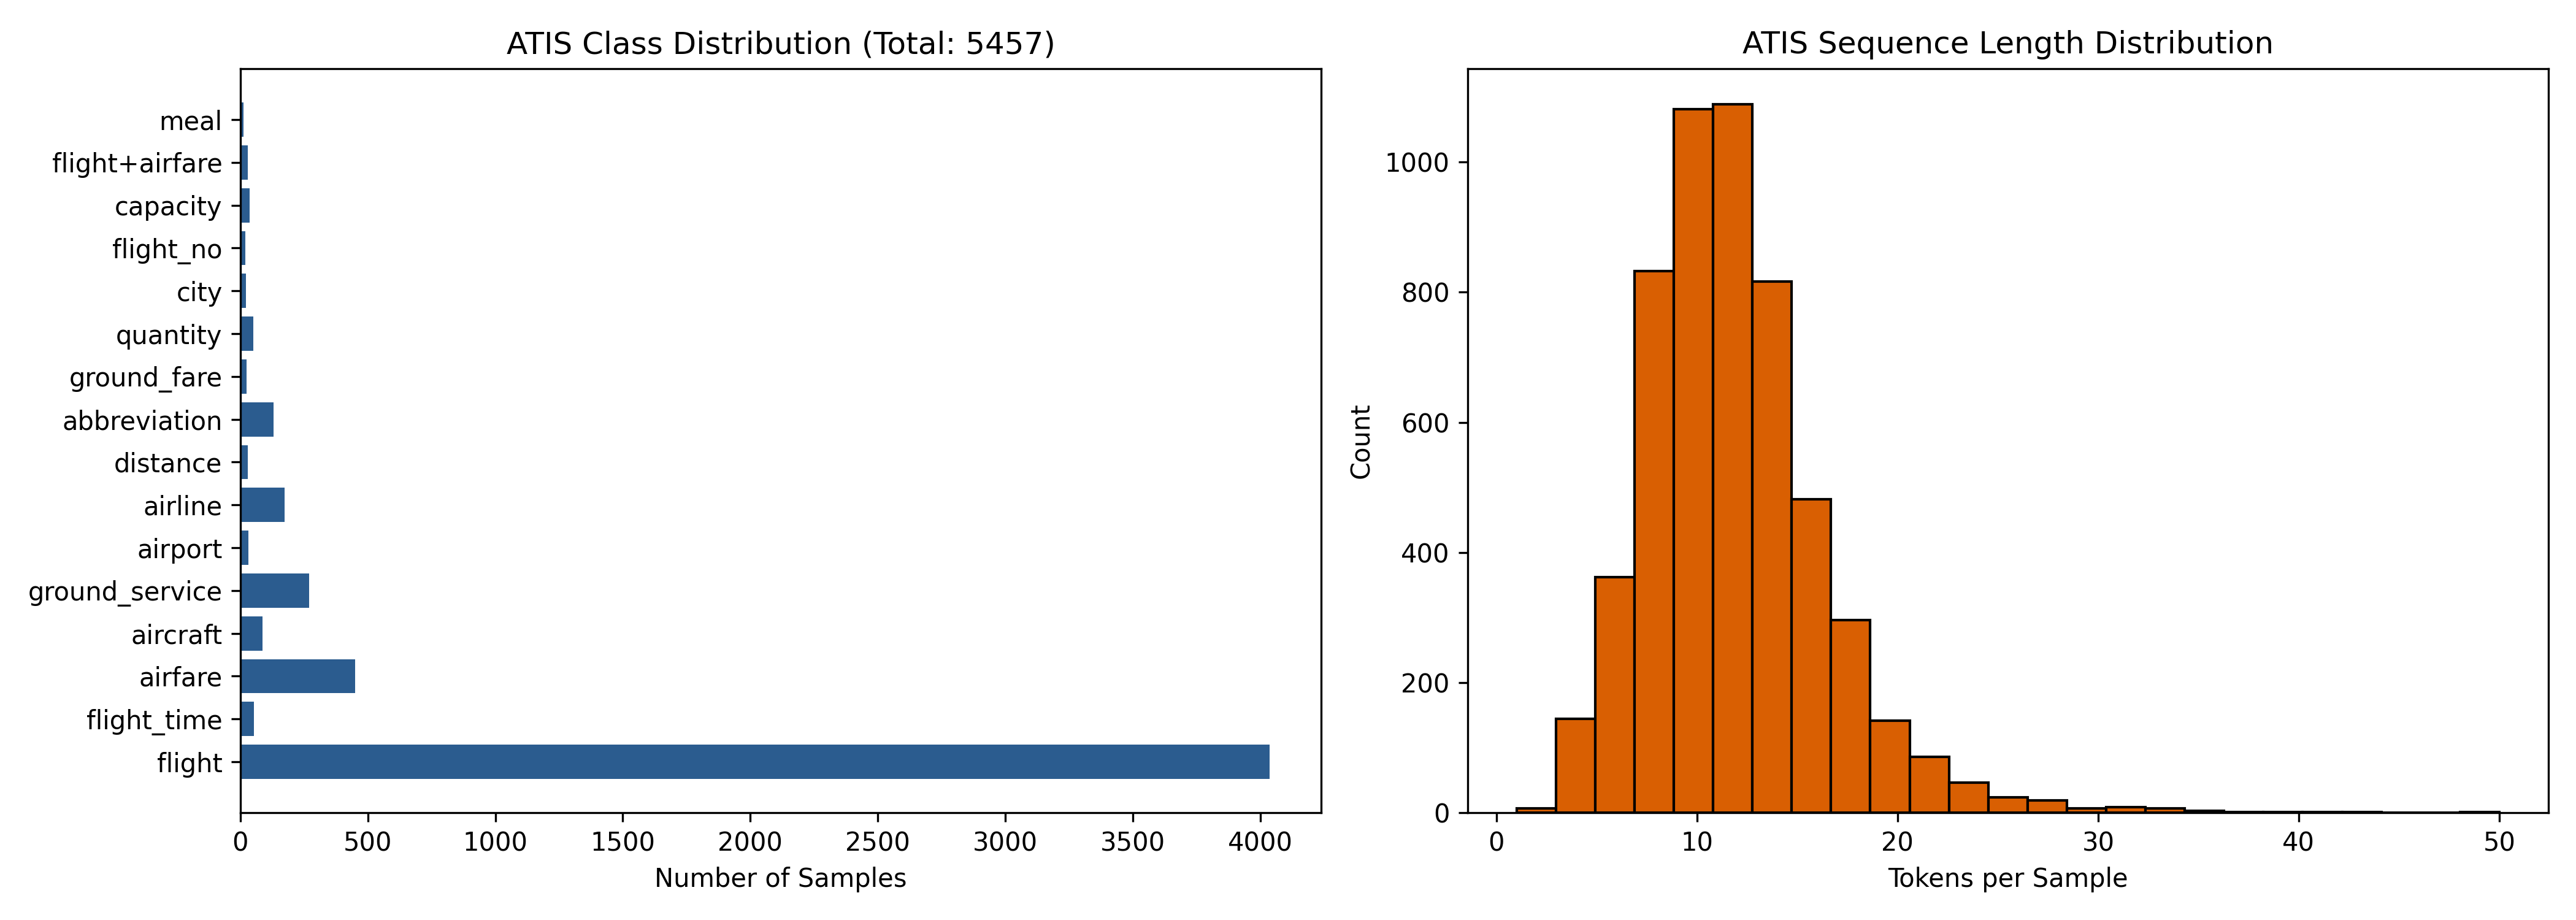

In [4]:
display(Image('artifacts/snips_eda_distribution.png', width=850))
display(Image('artifacts/atis_eda_distribution.png', width=850))

## Training and results

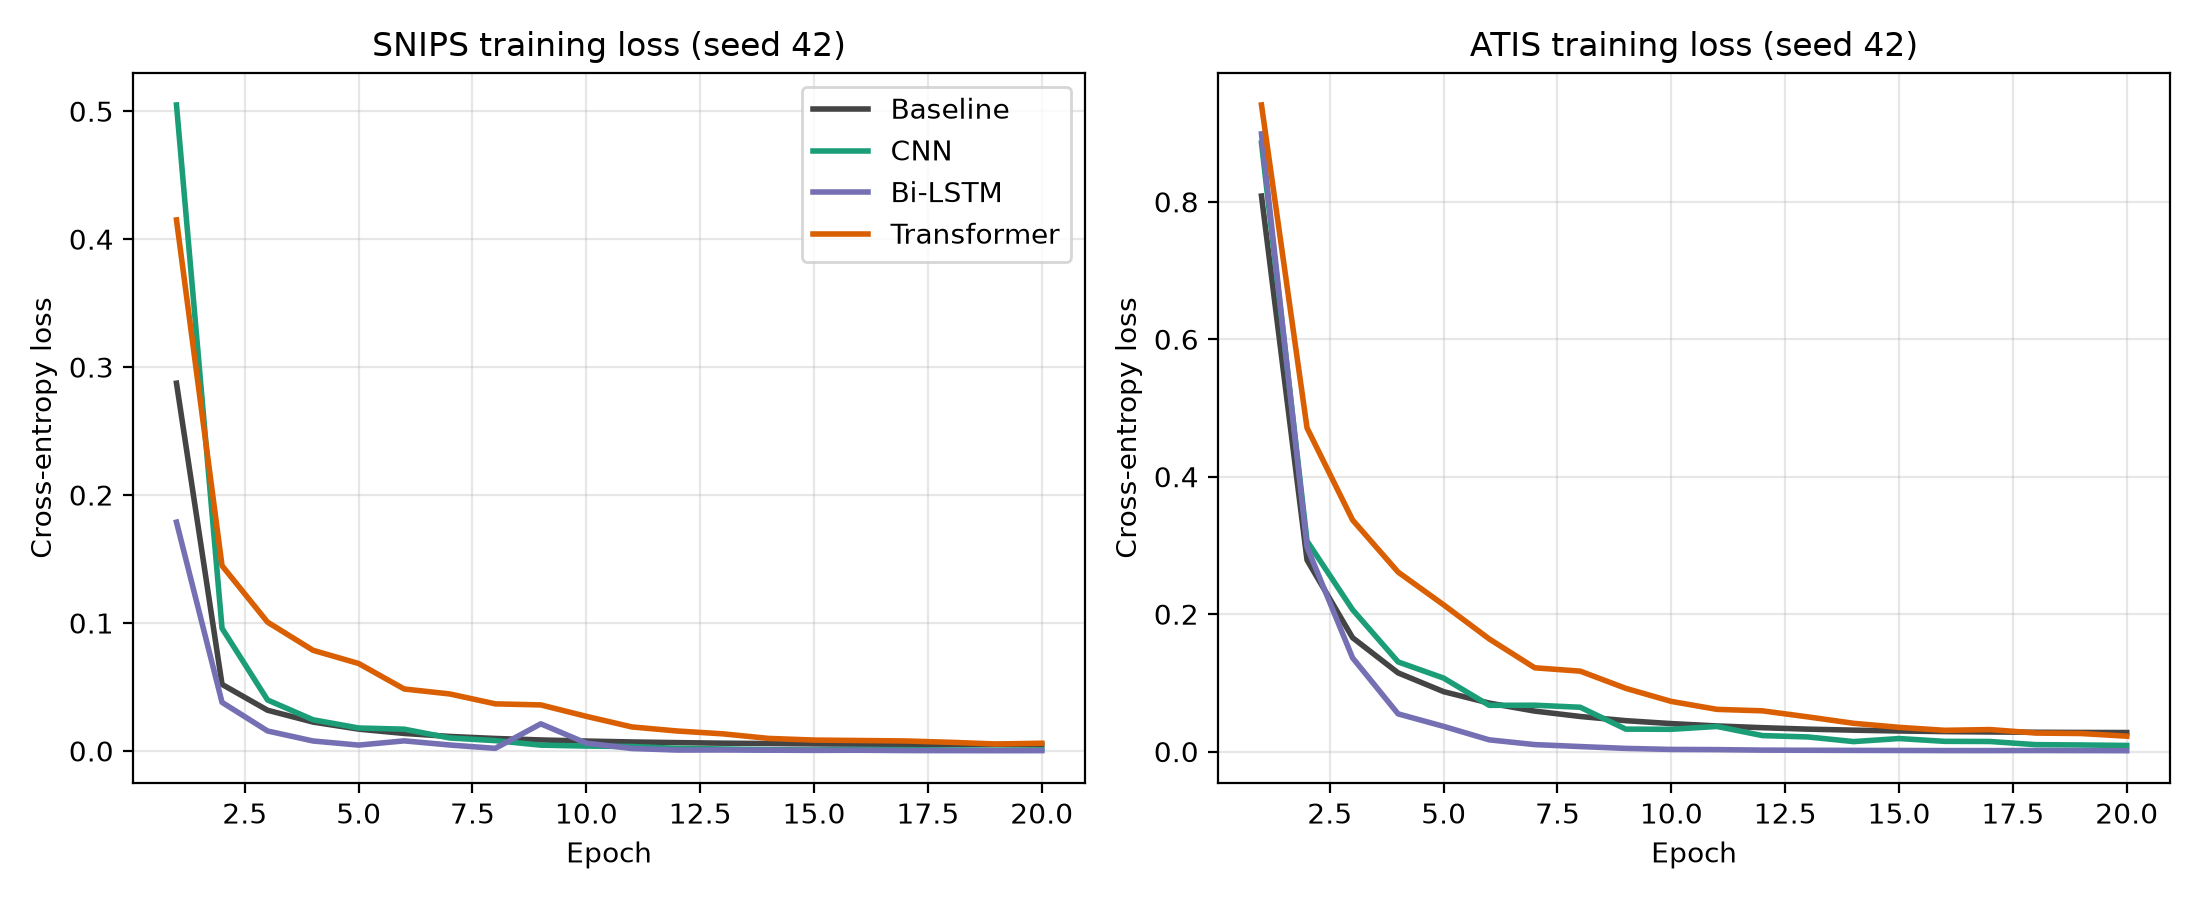

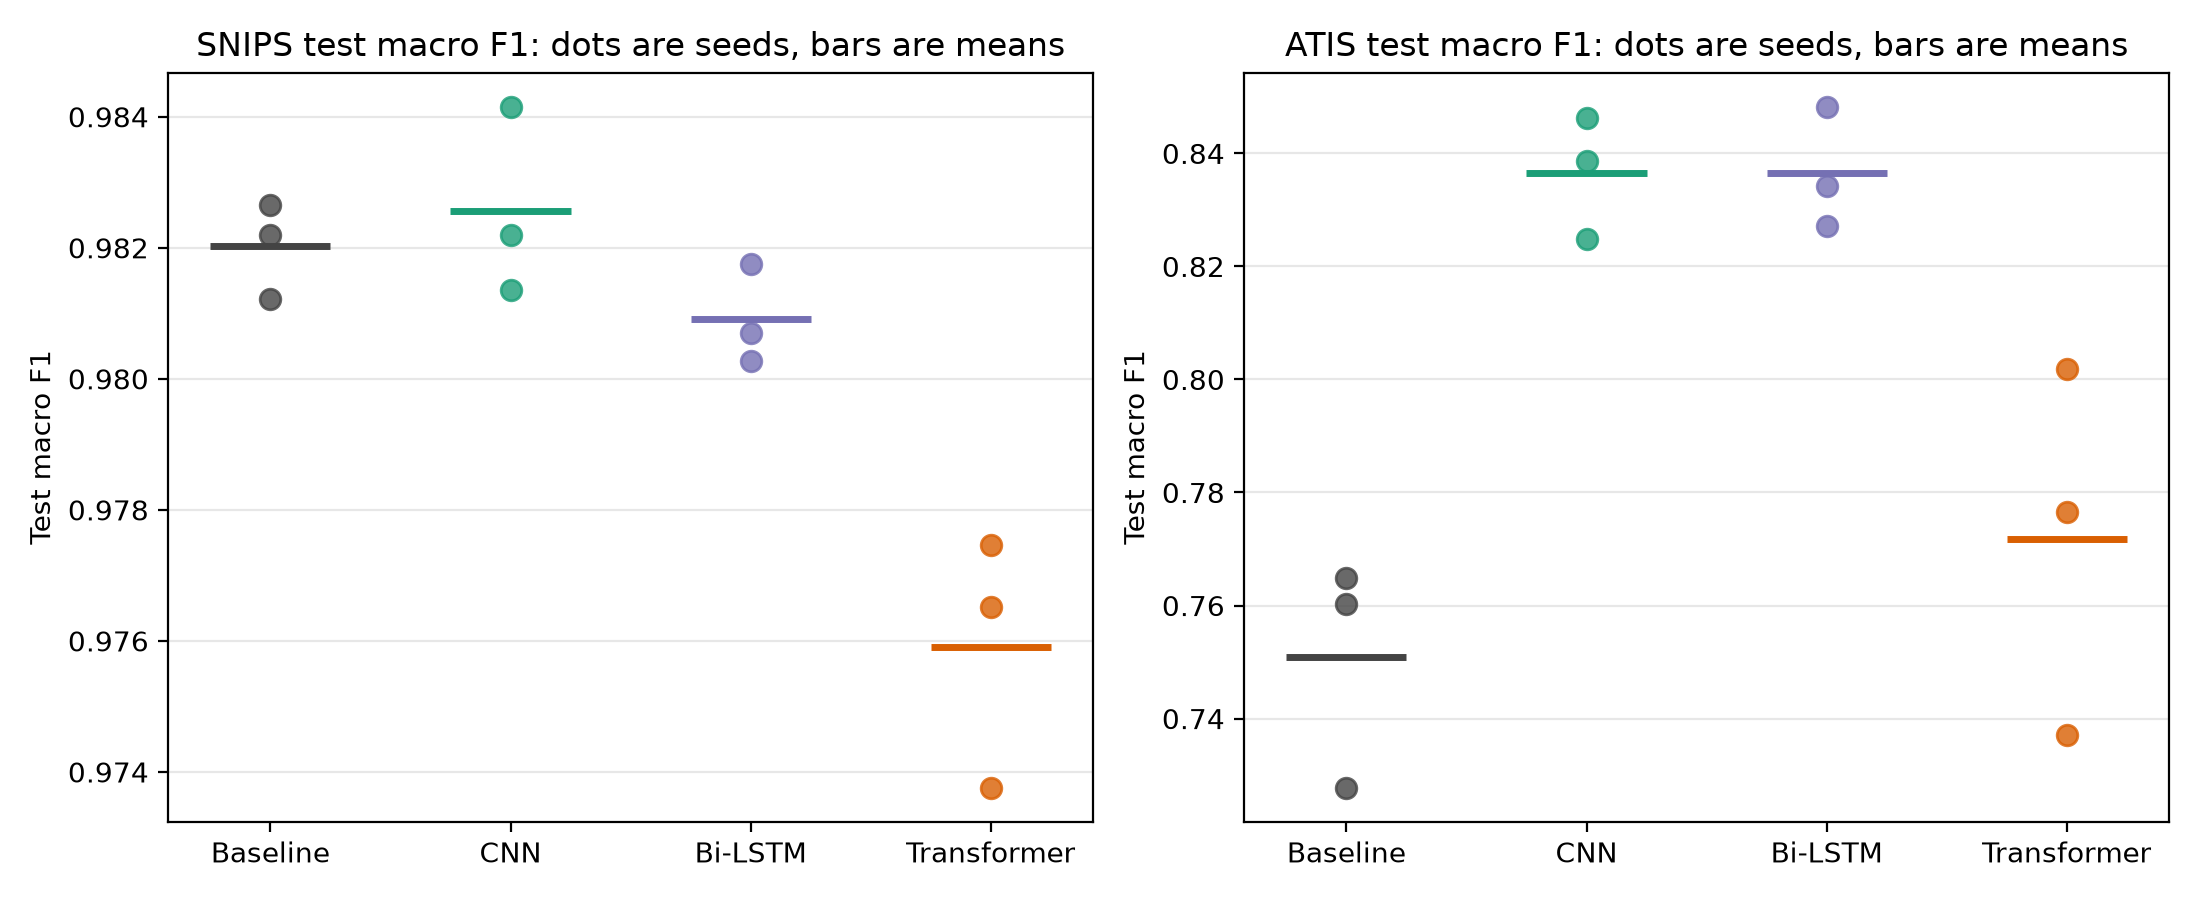

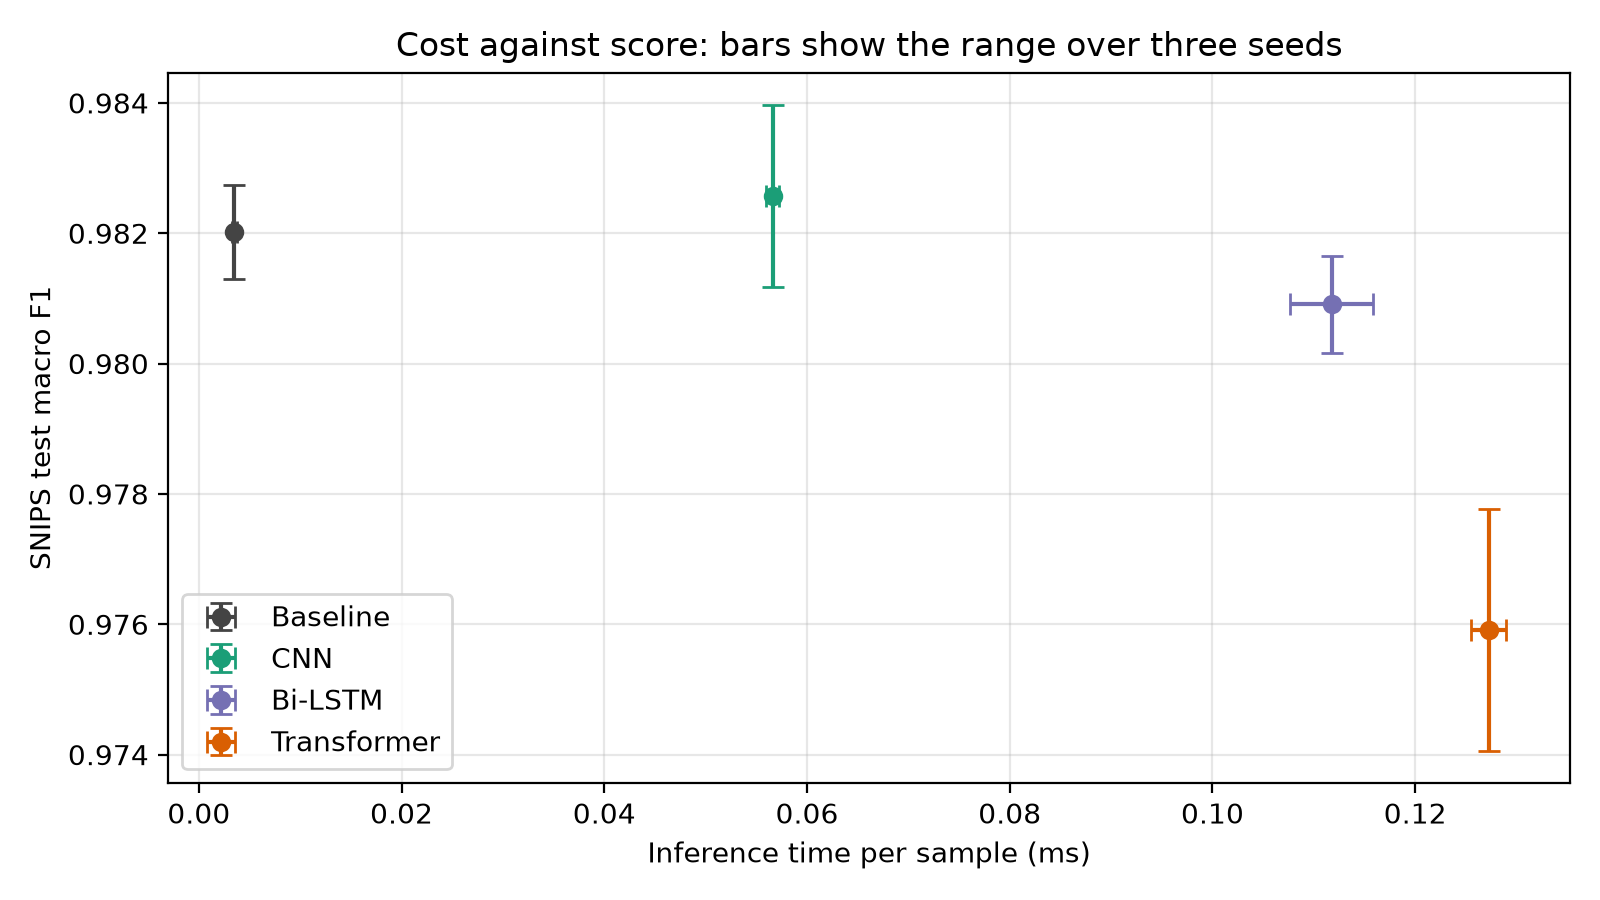

In [5]:
for name in ['figure1_loss_convergence', 'figure2_dataset_generalization', 'figure3_cost_vs_f1']:
    display(Image(f'artifacts/{name}.png', width=850))

## Confusion matrices
Built from each trained model's saved test predictions (SNIPS, seed 42).

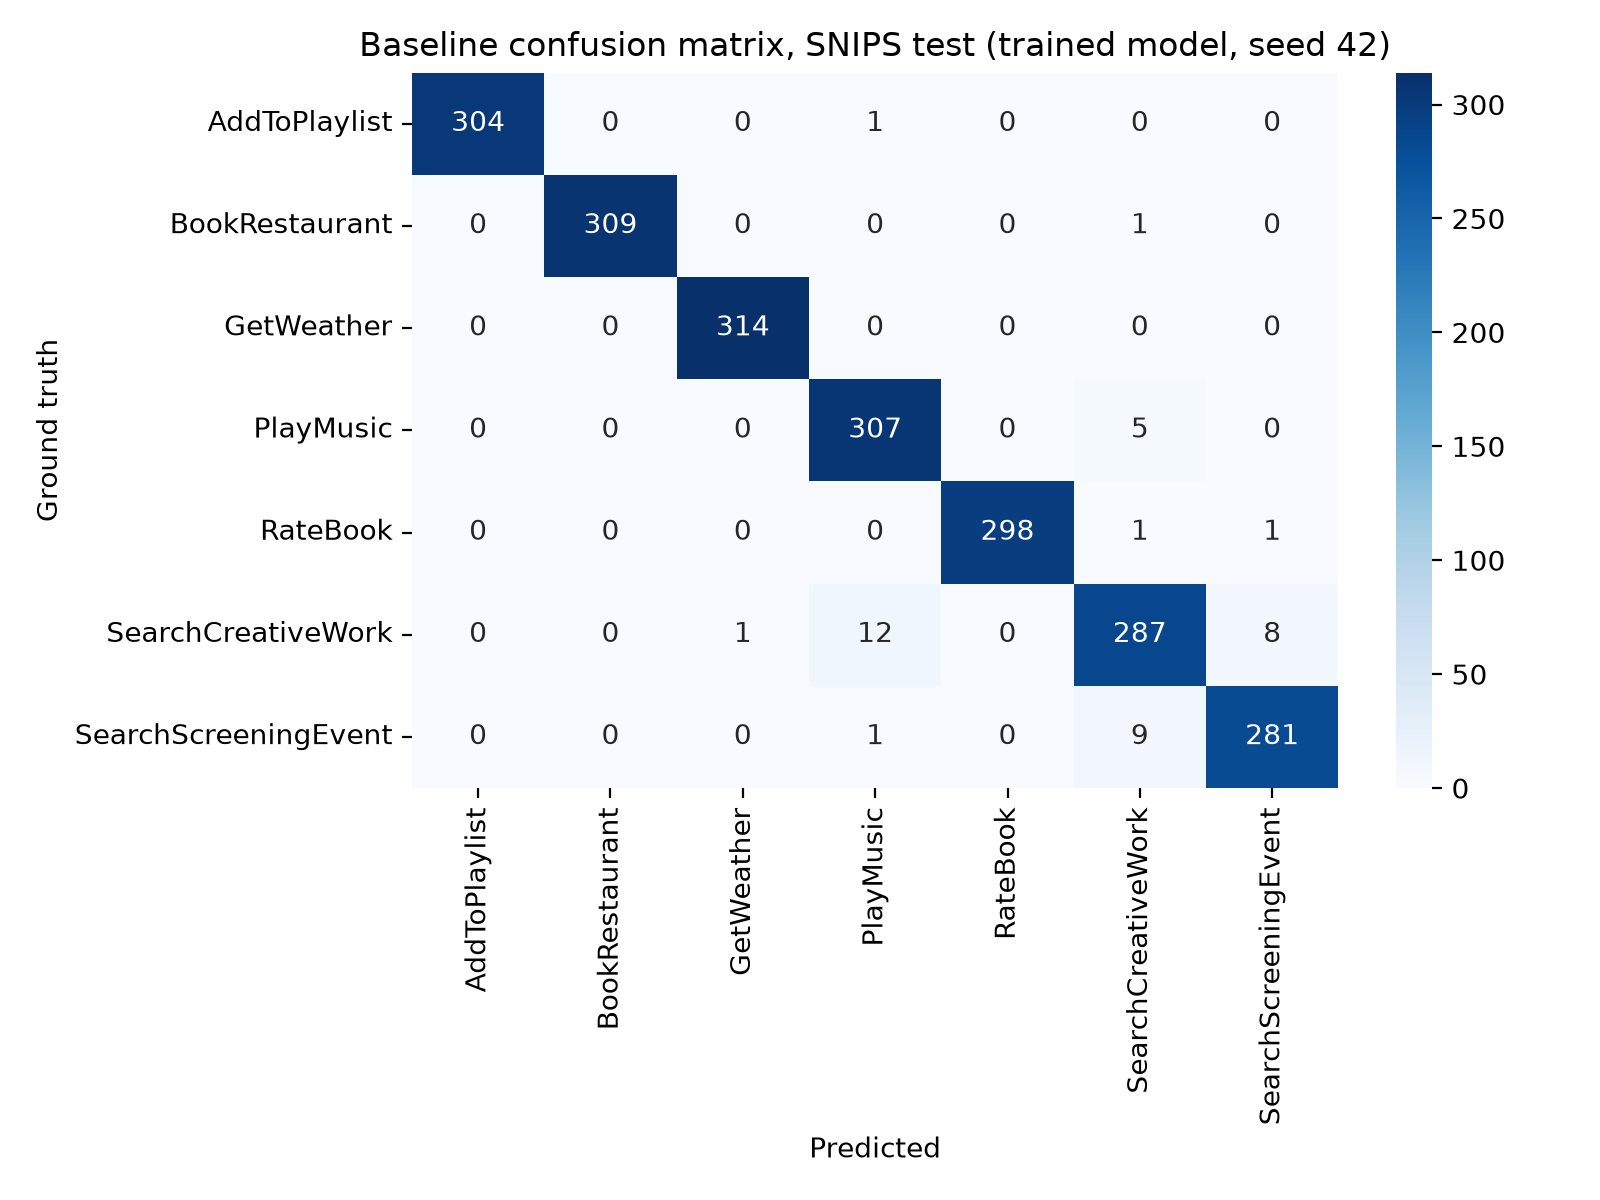

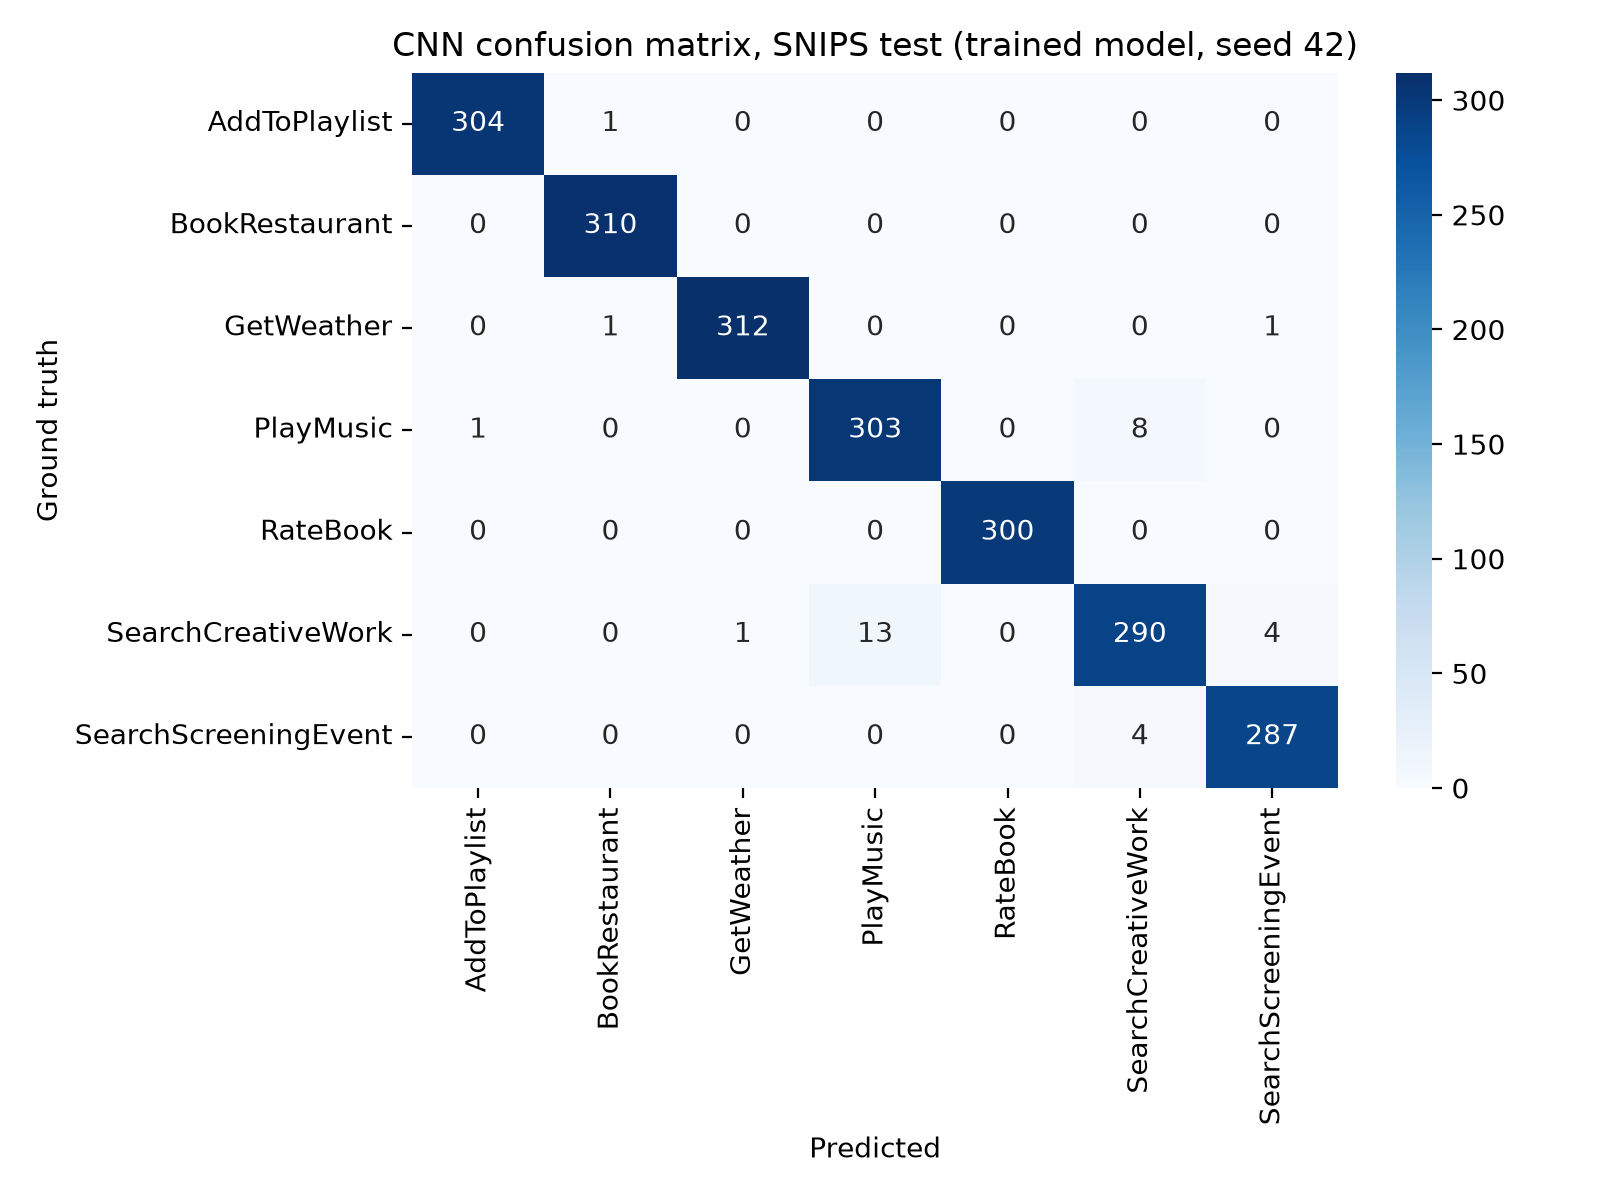

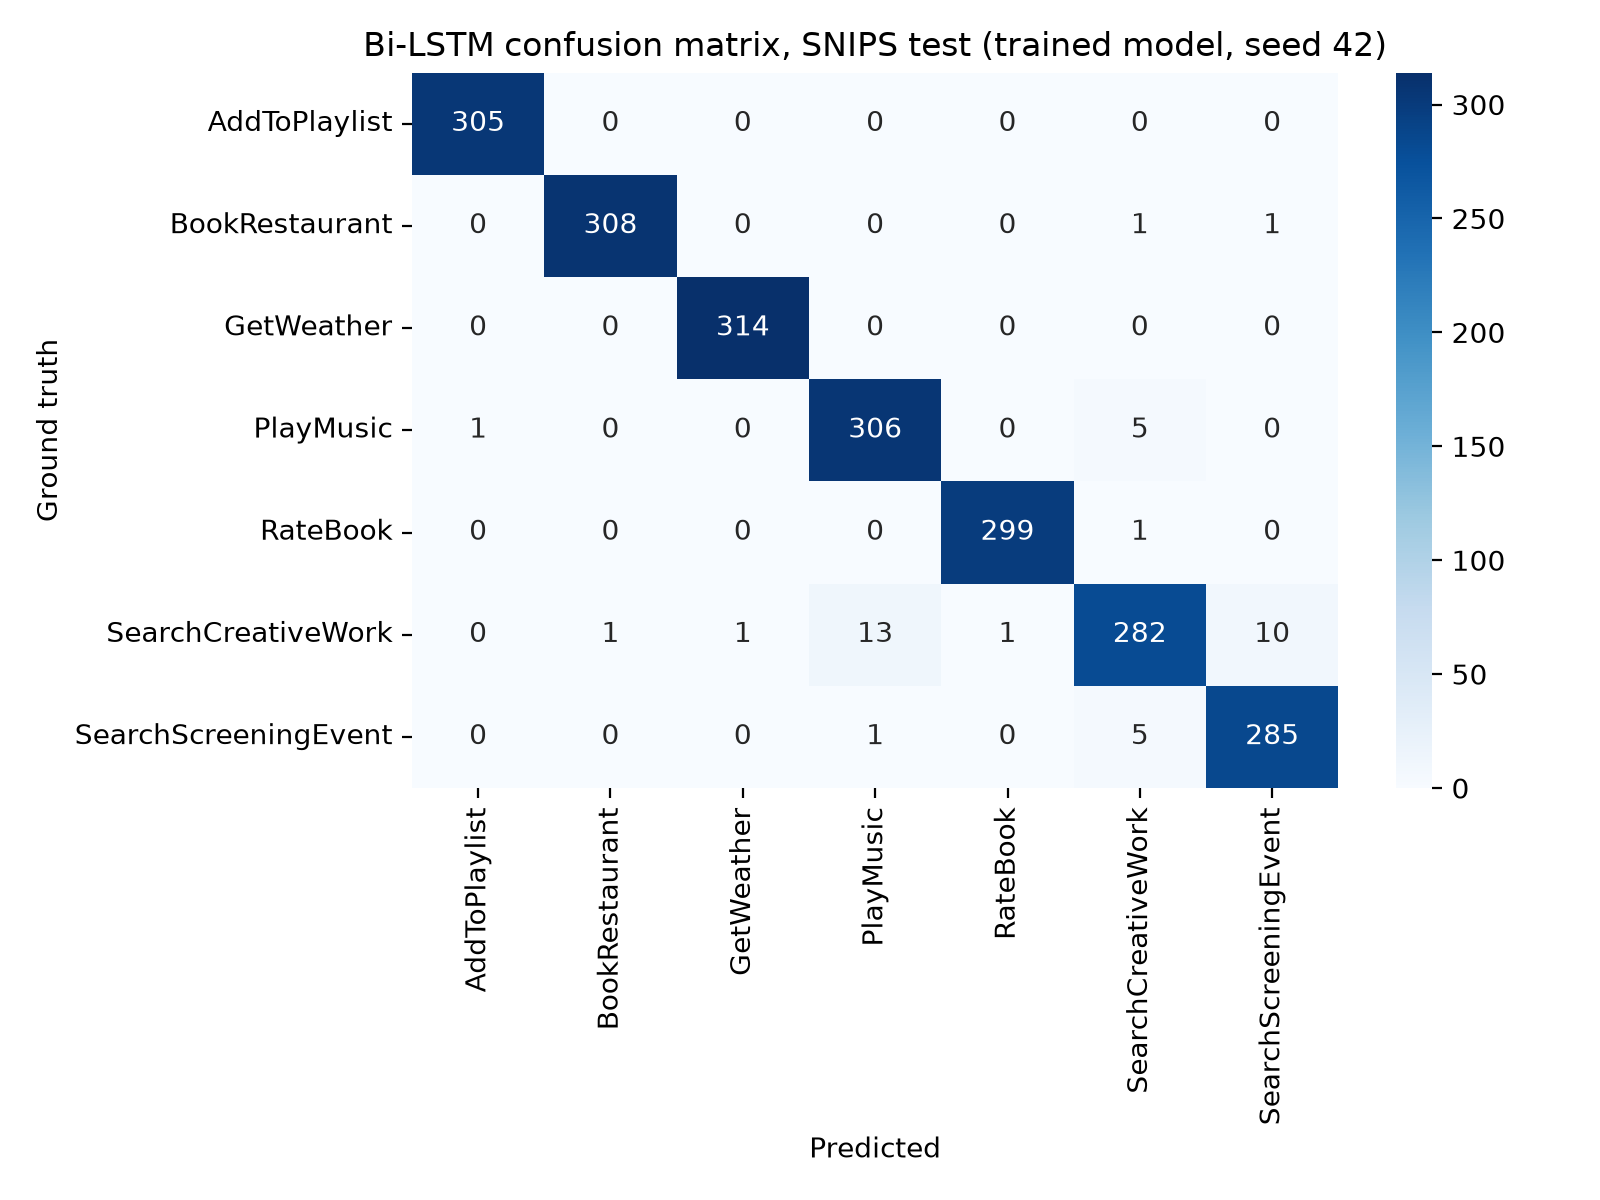

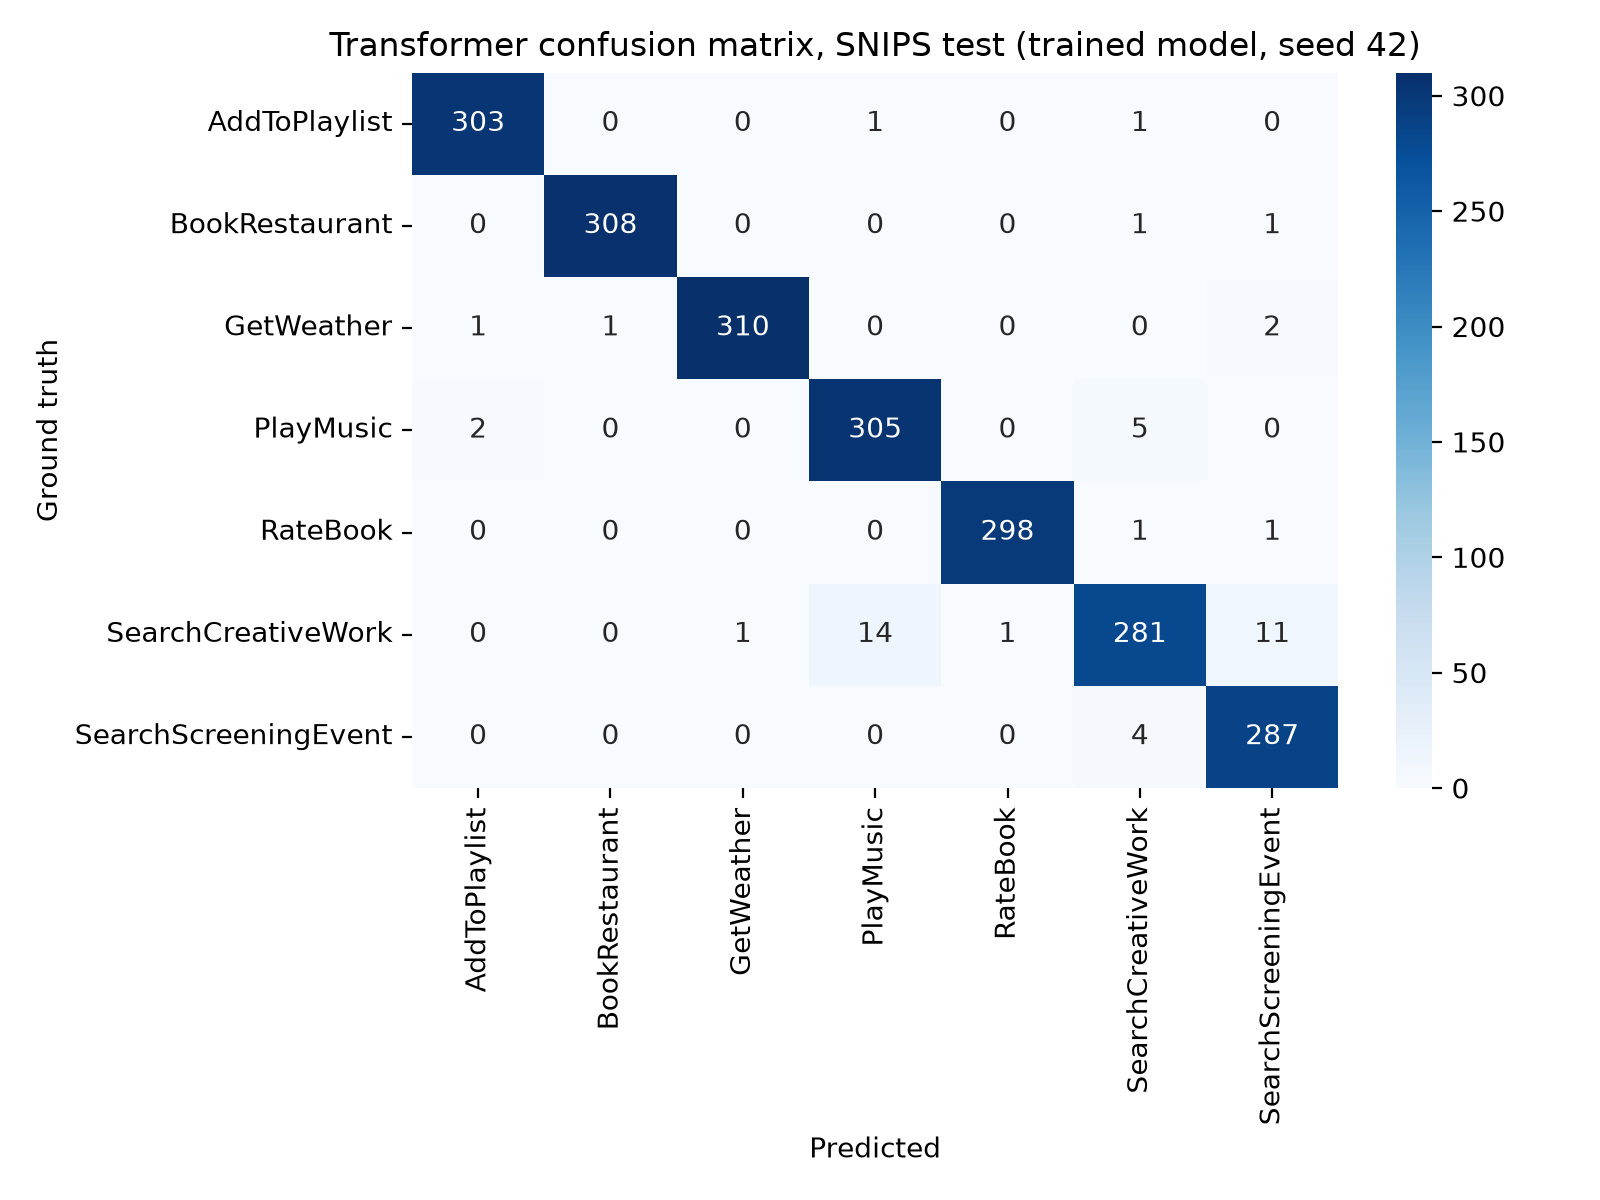

In [6]:
for name in ['baseline', 'cnn', 'rnn', 'transformer']:
    display(Image(f'artifacts/{name}_confusion_matrix.png', width=600))